# AMAC-ECG — Stage 5 Explainability and Model Analysis

This notebook implements the project's Stage 5 explainability and model-analysis workflow using **SHAP-based feature attribution**. It produces class-wise explanations, waveform-region and RR-feature summaries, faithfulness comparisons, and model-efficiency measurements.

## Stage 5 workflow
1. SHAP feature attribution for the selected CNN + Focal Loss + RR model.
2. Aggregate waveform attribution over the project's frozen P, QRS and T sample regions; report RR features separately.
3. Faithfulness comparison: masking the top 20% SHAP-ranked waveform samples versus random masks of equal size.
4. Model efficiency: parameter count, checkpoint size and inference latency.
5. Save reproducible JSON, CSV and PNG outputs under `artifacts/stage5/`.

**Important protocol:** use DS1 only to fit the selected model (fixed patient-held-out fold 0 for early stopping). Use DS2 only for post-fit explanation/evaluation samples; do not tune the model or SHAP settings using DS2. Existing project records disclose historical DS2 access, so this notebook does not claim DS2 was historically untouched.

**Execution:** run cells sequentially. Do not use “Run all” until preflight and package checks pass.

## Validation status
The notebook has been statically checked against the current repository APIs and its Python cells pass syntax validation. The standalone helper module passes shape-normalization unit tests. A complete Colab run has **not** been performed in this handover, because it requires your full companion package and a live Colab runtime/GPU. Runtime-dependent failures cannot honestly be ruled out before that execution.


## 1. Clone or refresh the project repository

In [1]:
from pathlib import Path
import subprocess, os, sys, json, time, hashlib, platform, zipfile, shutil
REPO = Path("/content/AMAC-ECG")
if REPO.exists():
    subprocess.run(["git", "-C", str(REPO), "pull", "origin", "main"], check=True)
else:
    subprocess.run(["git", "clone", "https://github.com/sanjanapriyadarsini/AMAC-ECG.git", str(REPO)], check=True)
os.chdir(REPO)
print("Repository:", REPO)
print("Top-level:", sorted(p.name for p in REPO.iterdir())[:30])

Repository: /content/AMAC-ECG
Top-level: ['.git', '.gitignore', 'DATA_README.txt', 'IMPORTANT_BEFORE_RUNNING.txt', 'RUN_ORDER_CORRECTED.md', 'Stage 4 – Final Evaluation and Decision Layer', 'Stage-2-CNN', 'artifacts', 'requirements.txt', 'src', 'stage1.md', 'stage2.md', 'stage3.md', 'stage4.md']


## 2. Install dependencies

In [2]:
%cd /content/AMAC-ECG
!pip -q install -r requirements.txt
!pip -q install shap tabulate


/content


## 3. Upload the Stage 4 complete companion package

Upload `AMAC_ECG_Stage4_Final_Complete_Package.zip` (the complete runtime package, not the paper-handover ZIP or results-only ZIP). It must contain processed DS1/DS2, frozen folds, DS1 OOF files, and `stage4.py` / project source as described in its README.

This runtime package is used to load the already prepared project assets. Do not upload raw patient data separately.

In [4]:

from google.colab import files
from pathlib import Path
import zipfile
import shutil

uploaded = files.upload()
zip_names = [n for n in uploaded if n.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload exactly one companion ZIP."

PACKAGE = zip_names[0]
REPO = Path("/content/AMAC-ECG").resolve()

required = {
    "artifacts/ds1.npz",
    "artifacts/ds2.npz",
    "src/folds.json",
    "src/config.py",
    "src/models.py",
    "src/train_cnn.py",
    "src/imbalance.py",
}

with zipfile.ZipFile(PACKAGE) as zf:
    files_in_zip = [
        n for n in zf.namelist()
        if not n.endswith("/")
    ]

    # Remove one common parent folder, if present
    parts = [Path(n).parts for n in files_in_zip]
    common_root = (
        parts[0][0]
        if parts and all(p[0] == parts[0][0] for p in parts)
        else None
    )

    normalized = {}
    for name in files_in_zip:
        p = Path(name)
        if common_root and p.parts[0] == common_root:
            p = Path(*p.parts[1:])
        normalized[p.as_posix()] = name

    missing = required - set(normalized)
    oof = [
        n for n in normalized
        if n.startswith("artifacts/preds/")
        and n.endswith(".npz")
    ]

    assert not missing, f"Missing files: {sorted(missing)}"
    assert len(oof) == 50, f"Expected 50 OOF files, found {len(oof)}"

    for relative, original in normalized.items():
        target = (REPO / relative).resolve()
        assert target == REPO or REPO in target.parents, relative
        target.parent.mkdir(parents=True, exist_ok=True)

        with zf.open(original) as src, open(target, "wb") as dst:
            shutil.copyfileobj(src, dst)

print("COMPANION PACKAGE CHECK PASSED")
print("DS1 and DS2: Present")
print("Frozen folds: Present")
print("DS1 OOF files:", len(oof))
print("Source files: Present")


Saving AMAC_ECG_Stage4_Final_Complete_Package.zip to AMAC_ECG_Stage4_Final_Complete_Package (1).zip
COMPANION PACKAGE CHECK PASSED
DS1 and DS2: Present
Frozen folds: Present
DS1 OOF files: 50
Source files: Present


## 4. Preflight: dataset identity, patient split and model inputs

In [5]:
import numpy as np
sys.path.insert(0, str(REPO / "src"))
import config as C
from pathlib import Path

ART = REPO / "artifacts"
OUT = ART / "stage5"
# Start a clean Stage 5 output directory so stale files cannot be mixed in.
if OUT.exists():
    shutil.rmtree(OUT)
OUT.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

DS1_HASH_EXPECTED = "74bfdda3fe8d2d73b13b00596271eb15418ee1bd13046e0aa7e42186eba54644"
DS2_HASH_EXPECTED = "5e4269ad60fc37d6b9fefe9fc2c6d038ada7d989548ecb902053ab70c45b2fea"
h1, h2 = sha256(ART / "ds1.npz"), sha256(ART / "ds2.npz")
assert h1 == DS1_HASH_EXPECTED, f"DS1 hash mismatch: {h1}"
assert h2 == DS2_HASH_EXPECTED, f"DS2 hash mismatch: {h2}"

with np.load(ART / "ds1.npz", allow_pickle=False) as z:
    ds1 = {k: z[k] for k in z.files}
with np.load(ART / "ds2.npz", allow_pickle=False) as z:
    ds2 = {k: z[k] for k in z.files}

required_arrays = {"X", "rr", "y", "pid"}
assert required_arrays.issubset(ds1), f"DS1 missing arrays: {required_arrays-set(ds1)}"
assert required_arrays.issubset(ds2), f"DS2 missing arrays: {required_arrays-set(ds2)}"
assert ds1["X"].shape == (53111, 216) and ds1["rr"].shape == (53111, 4)
assert ds2["X"].shape == (47534, 216) and ds2["rr"].shape == (47534, 4)
assert ds1["y"].shape == (53111,) and ds2["y"].shape == (47534,)
assert ds1["pid"].shape == (53111,) and ds2["pid"].shape == (47534,)
assert len(np.unique(ds1["pid"])) == 22
assert len(np.unique(ds2["pid"])) == 21
assert np.isfinite(ds1["X"]).all() and np.isfinite(ds1["rr"]).all()
assert np.isfinite(ds2["X"]).all() and np.isfinite(ds2["rr"]).all()
assert set(np.unique(ds1["y"])).issubset(set(range(5)))
assert set(np.unique(ds2["y"])).issubset(set(range(5)))
assert C.SEGMENTS == {"P": (0, 54), "QRS": (54, 108), "T": (108, 216)}
print("PREFLIGHT PASS")
print("DS1:", ds1["X"].shape, "patients:", len(np.unique(ds1["pid"])))
print("DS2:", ds2["X"].shape, "patients:", len(np.unique(ds2["pid"])))
print("Frozen waveform segments:", C.SEGMENTS)


PREFLIGHT PASS
DS1: (53111, 216) patients: 22
DS2: (47534, 216) patients: 21
Frozen waveform segments: {'P': (0, 54), 'QRS': (54, 108), 'T': (108, 216)}


## 5. Load the frozen patient-grouped DS1 fold

Use the repository's existing `src/folds.json`; do not regenerate folds. Fold 0 is held out for CNN early stopping, matching the Stage 4 setup.

In [6]:
fold_spec = json.loads((REPO / "src" / "folds.json").read_text())
assert fold_spec["ds1_sha256"] == DS1_HASH_EXPECTED
patient_fold = {str(k): int(v) for k, v in fold_spec["patient_fold"].items()}
assert set(patient_fold) == {str(x) for x in np.unique(ds1["pid"])}
assert set(patient_fold.values()) == {0, 1, 2, 3, 4}
assign = np.array([patient_fold[str(p)] for p in ds1["pid"]], dtype=int)
tr_idx = np.where(assign != 0)[0]
va_idx = np.where(assign == 0)[0]
assert not (set(ds1["pid"][tr_idx]) & set(ds1["pid"][va_idx]))
assert len(tr_idx) == 45076 and len(va_idx) == 8035, (
    f"Fold-0 split differs from audited Stage 4 split: "
    f"train={len(tr_idx)}, validation={len(va_idx)}"
)
print("Frozen fold-0 split verified.")
print("Train beats:", len(tr_idx), "Validation beats:", len(va_idx))
print("Patient overlap:", len(set(ds1["pid"][tr_idx]) & set(ds1["pid"][va_idx])))


Frozen fold-0 split verified.
Train beats: 45076 Validation beats: 8035
Patient overlap: 0


## 6. Fit selected model and save checkpoint

Selected model: **CNN + Focal Loss + RR, seed 0**. The CNN is fitted on DS1 training patients and early-stopped on the fixed DS1 fold-0 validation patients. DS2 is not passed to training.

This cell trains the model if no Stage 4 checkpoint exists. The resulting checkpoint is a newly saved artifact from the declared DS1-only fitting procedure; it is not represented as a recovered historical checkpoint.

In [7]:
import torch
from models import make_cnn, count_params
from train_cnn import train_cnn

device = "cuda" if torch.cuda.is_available() else "cpu"
checkpoint_dir = OUT / "models"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "cnn_focal_rr_seed0_stage5.pt"

# Fit only on DS1 training patients. DS2 is never passed to train_cnn().
_, train_meta = train_cnn(
    ds1["X"][tr_idx], ds1["rr"][tr_idx], ds1["y"][tr_idx],
    ds1["X"][va_idx], ds1["rr"][va_idx], ds1["y"][va_idx],
    use_rr=True, strategy="focal", seed=0, device=device,
    verbose=True, return_model=True
)
assert "model" in train_meta, "train_cnn(return_model=True) did not return model."
model = train_meta["model"].to(device).eval()
torch.save({
    "state_dict": model.state_dict(),
    "model": "CNN + Focal Loss + RR",
    "seed": 0,
    "validation_fold": 0,
    "ds1_sha256": h1,
}, checkpoint_path)
print("Saved DS1-trained checkpoint:", checkpoint_path)
print("Best epoch:", train_meta.get("best_epoch"))
print("Validation Macro-F1:", train_meta.get("best_val_macro_f1"))
print("Trainable parameters:", count_params(model))


      ep   0  loss 0.0079  val macroF1 0.3744  *
      ep   2  loss 0.0031  val macroF1 0.4462  *
      ep   5  loss 0.0015  val macroF1 0.3864
      ep  10  loss 0.0019  val macroF1 0.4543  *
      ep  15  loss 0.0002  val macroF1 0.4252
      ep  20  loss 0.0007  val macroF1 0.4095
      ep  21  loss 0.0000  val macroF1 0.4618  *
      ep  25  loss 0.0041  val macroF1 0.4107
      ep  30  loss 0.0004  val macroF1 0.4153
      early stop at epoch 33
Saved DS1-trained checkpoint: /content/AMAC-ECG/artifacts/stage5/models/cnn_focal_rr_seed0_stage5.pt
Best epoch: 21
Validation Macro-F1: 0.46182682620769844
Trainable parameters: 146189


### Stage 5 helper module

The next cell writes `src/stage5_utils.py` into the cloned repository and imports the tested helper functions used for SHAP output normalization, masking faithfulness, and latency measurement. The same `.py` file is supplied separately with this handover.

In [8]:
# Write the companion utility module into the repository.
from pathlib import Path
helper_source = r'''"""Utility functions used by the AMAC-ECG Stage 5 SHAP notebook.

This module contains deterministic shape normalization and perturbation/
benchmark helpers. It does not load datasets, train models, or create data.
"""
from __future__ import annotations

import numpy as np


def normalize_shap_values(values, n_samples: int, n_features: int,
                          n_classes: int = 5) -> np.ndarray:
    """Return multi-output SHAP values in (samples, features, classes) order."""
    # shap.KernelExplainer normally returns a list (one array per output)
    # on older SHAP releases and a 3-D ndarray on newer releases.
    if hasattr(values, "values"):  # shap.Explanation
        values = values.values

    if isinstance(values, list):
        arrays = [np.asarray(v) for v in values]
        if len(arrays) != n_classes:
            raise ValueError(
                f"Expected {n_classes} output arrays, received {len(arrays)}"
            )
        if any(a.shape != (n_samples, n_features) for a in arrays):
            raise ValueError(
                "List SHAP output must contain arrays shaped "
                f"{(n_samples, n_features)}; got {[a.shape for a in arrays]}"
            )
        arr = np.stack(arrays, axis=-1)
    else:
        arr = np.asarray(values)
        candidates = []
        if arr.shape == (n_samples, n_features, n_classes):
            candidates.append(arr)
        if arr.shape == (n_classes, n_samples, n_features):
            candidates.append(np.moveaxis(arr, 0, -1))
        if arr.shape == (n_samples, n_classes, n_features):
            candidates.append(np.moveaxis(arr, 1, -1))
        if len(candidates) != 1:
            raise ValueError(
                "Ambiguous or unsupported SHAP output shape "
                f"{arr.shape}; expected samples={n_samples}, "
                f"features={n_features}, classes={n_classes}"
            )
        arr = candidates[0]

    if arr.shape != (n_samples, n_features, n_classes):
        raise ValueError(
            f"Normalized SHAP shape is {arr.shape}, expected "
            f"{(n_samples, n_features, n_classes)}"
        )
    if not np.isfinite(arr).all():
        raise ValueError("SHAP output contains NaN or infinite values")
    return arr.astype(np.float64, copy=False)


def masking_faithfulness(predict_fn, waveform: np.ndarray, rr: np.ndarray,
                         waveform_shap: np.ndarray, *, mask_fraction: float = 0.20,
                         random_repeats: int = 20,
                         rng: np.random.Generator) -> dict:
    """Compare true-class probability drop for SHAP-ranked vs random zero masks."""
    waveform = np.asarray(waveform, dtype=np.float32).reshape(-1)
    rr = np.asarray(rr, dtype=np.float32).reshape(-1)
    attribution = np.asarray(waveform_shap, dtype=np.float64).reshape(-1)

    if waveform.shape != attribution.shape:
        raise ValueError("Waveform and waveform SHAP vectors must have equal length")
    if not 0 < mask_fraction < 1:
        raise ValueError("mask_fraction must be between 0 and 1")
    if random_repeats < 2:
        raise ValueError("Use at least two random masks to estimate SD")

    n = len(waveform)
    k = max(1, int(np.ceil(mask_fraction * n)))
    base = np.concatenate([waveform, rr])[None, :]
    base_prob = np.asarray(predict_fn(base))[0]
    if base_prob.ndim != 1:
        raise ValueError("Prediction function must return (rows, classes)")
    # Caller sets class_index after receiving this result; all class scores
    # are returned to keep the helper generic.
    ranked = np.argsort(np.abs(attribution))[-k:]
    x_top = waveform.copy()
    x_top[ranked] = 0.0
    top_prob = np.asarray(predict_fn(np.concatenate([x_top, rr])[None, :]))[0]

    random_drops = []
    for _ in range(random_repeats):
        idx = rng.choice(n, size=k, replace=False)
        x_random = waveform.copy()
        x_random[idx] = 0.0
        p_random = np.asarray(
            predict_fn(np.concatenate([x_random, rr])[None, :])
        )[0]
        random_drops.append(base_prob - p_random)

    return {
        "base_probabilities": base_prob,
        "top_mask_probabilities": top_prob,
        "random_probability_drops": np.asarray(random_drops),
        "masked_positions": int(k),
        "mask_fraction": float(mask_fraction),
    }


def benchmark_inference(model, x_tensor, rr_tensor, *, device: str,
                        warmup: int = 10, repeats: int = 50) -> float:
    """Return mean forward-pass milliseconds per batch; excludes warmup."""
    import time
    import torch

    if len(x_tensor) != len(rr_tensor) or len(x_tensor) == 0:
        raise ValueError("Benchmark tensors must have equal, non-zero batch size")
    model.eval()
    with torch.inference_mode():
        for _ in range(warmup):
            model(x_tensor, rr_tensor)
        if device.startswith("cuda"):
            torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(repeats):
            model(x_tensor, rr_tensor)
        if device.startswith("cuda"):
            torch.cuda.synchronize()
    return (time.perf_counter() - start) * 1000.0 / repeats
'''
(REPO / "src" / "stage5_utils.py").write_text(helper_source, encoding="utf-8")
sys.path.insert(0, str(REPO / "src"))
from stage5_utils import normalize_shap_values, masking_faithfulness, benchmark_inference
print("Stage 5 helper module installed.")


Stage 5 helper module installed.


## 7. SHAP setup and bounded explanation sample

Use KernelSHAP on the complete 220-input representation (216 waveform samples + 4 RR features). The prediction wrapper returns the model's five class probabilities. To keep runtime manageable, use a small DS1 background sample and a small, fixed number of DS2 examples per evaluated class. These settings are computational limits, not model-selection choices.

If SHAP is too slow on the available runtime, reduce `EXPLAIN_PER_CLASS` and `NSAMPLES`; do not change the dataset split or model.

In [9]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

FEATURE_NAMES = [f"wave_{i:03d}" for i in range(216)] + [
    "pre_rr", "post_rr", "local_ratio", "global_ratio"
]
N_BACKGROUND = 12
EXPLAIN_PER_CLASS = 4
NSAMPLES = 100
rng = np.random.default_rng(505)

# SHAP background is drawn only from DS1 training patients, not fold-0 validation.
bg_idx = rng.choice(tr_idx, size=min(N_BACKGROUND, len(tr_idx)), replace=False)
background = np.column_stack([ds1["X"][bg_idx], ds1["rr"][bg_idx]]).astype(np.float32)

selected = []
for cls in C.EVAL_LABELS:
    ids = np.where(ds2["y"] == cls)[0]
    assert len(ids) > 0, f"DS2 has no examples for evaluation class {C.CLASS_NAMES[cls]}"
    selected.extend(
        rng.choice(ids, size=min(EXPLAIN_PER_CLASS, len(ids)), replace=False).tolist()
    )
selected = np.asarray(selected, dtype=int)
assert len(selected) == EXPLAIN_PER_CLASS * len(C.EVAL_LABELS)

explain_matrix = np.column_stack([
    ds2["X"][selected], ds2["rr"][selected]
]).astype(np.float32)
true_labels = ds2["y"][selected].astype(int)

def predict_proba_flat(z):
    z = np.asarray(z, dtype=np.float32)
    if z.ndim == 1:
        z = z.reshape(1, -1)
    assert z.ndim == 2 and z.shape[1] == 220, f"Expected (rows,220), got {z.shape}"
    x = torch.as_tensor(z[:, :216], dtype=torch.float32, device=device)
    rr = torch.as_tensor(z[:, 216:], dtype=torch.float32, device=device)
    model.eval()
    predictions = []
    with torch.inference_mode():
        for start in range(0, len(z), 256):
            logits = model(x[start:start+256], rr[start:start+256])
            predictions.append(torch.softmax(logits, dim=1).cpu().numpy())
    out = np.vstack(predictions)
    assert out.shape == (len(z), 5), f"Unexpected model output: {out.shape}"
    assert np.isfinite(out).all()
    return out

# KernelSHAP is model-agnostic. It estimates attributions; it does not retrain the model.
explainer = shap.KernelExplainer(predict_proba_flat, background)
shap_values_raw = explainer.shap_values(explain_matrix, nsamples=NSAMPLES)
print("SHAP calculation complete.")


  0%|          | 0/16 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/shap/explainers/_kernel.py:788: UserWarning: Linear regression equation is singular, a least squares solutions is used instead.
To avoid this situation and get a regular matrix do one of the following:
1) turn up the number of samples,
2) turn up the L1 regularization with num_features(N) where N is less than the number of samples,
3) group features together to reduce the number of inputs that need to be explained.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 8 iterations, i.e. alpha=1.711e-03, with an active set of 8 regressors, and the smallest cholesky pivot element being 5.960e-08. Reduce max_iter or increase eps parameters.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_least_angle.py:723: ConvergenceWarning: Regressors in active set degenerate. Dropping a regressor, after 

SHAP calculation complete.


## 8. Normalize SHAP output format and calculate class-wise feature attribution

SHAP versions return multi-output values in different layouts. This cell normalizes the output to `(samples, features, classes)` and stops if the returned dimensions are ambiguous.

In [10]:
sv = normalize_shap_values(
    shap_values_raw, n_samples=len(explain_matrix),
    n_features=220, n_classes=5
)
# Explain each sample's true-class output probability; this is a per-example,
# true-label-conditioned summary, not a predicted-class explanation.
true_class_shap = np.stack([
    sv[i, :, int(true_labels[i])] for i in range(len(selected))
])
mean_abs = np.mean(np.abs(true_class_shap), axis=0)

feature_importance = pd.DataFrame({
    "feature": FEATURE_NAMES,
    "mean_abs_shap_true_class": mean_abs
}).sort_values("mean_abs_shap_true_class", ascending=False)
feature_importance.to_csv(OUT / "shap_feature_importance.csv", index=False)

class_rows = []
for cls in C.EVAL_LABELS:
    mask = true_labels == cls
    cls_sv = sv[mask, :, cls]
    vals = np.mean(np.abs(cls_sv), axis=0)
    for j, name in enumerate(FEATURE_NAMES):
        class_rows.append({
            "class": C.CLASS_NAMES[cls], "feature": name,
            "mean_abs_shap": float(vals[j]), "n_samples": int(mask.sum())
        })
classwise_df = pd.DataFrame(class_rows)
classwise_df.to_csv(OUT / "shap_classwise_feature_importance.csv", index=False)
print(feature_importance.head(15))


      feature  mean_abs_shap_true_class
76   wave_076                  0.024114
216    pre_rr                  0.023585
43   wave_043                  0.016461
33   wave_033                  0.016252
208  wave_208                  0.014507
205  wave_205                  0.014239
171  wave_171                  0.013035
160  wave_160                  0.012475
27   wave_027                  0.011844
63   wave_063                  0.011369
206  wave_206                  0.010962
127  wave_127                  0.010886
34   wave_034                  0.010712
53   wave_053                  0.010685
75   wave_075                  0.009734


## 9. P / QRS / T and RR contribution summaries

Waveform attribution is aggregated using the project's fixed sample boundaries from `src/config.py`. RR values remain separate. These are attribution summaries over the selected explanation sample; they are not clinical validation or causal claims.

In [11]:
region_rows = []
for cls in C.EVAL_LABELS:
    mask = true_labels == cls
    if not mask.any():
        continue
    cls_sv = np.stack([sv[i, :, cls] for i in np.where(mask)[0]])
    abs_mean = np.mean(np.abs(cls_sv), axis=0)
    row = {"class": C.CLASS_NAMES[cls], "n_samples": int(mask.sum())}
    for region, (a,b) in C.SEGMENTS.items():
        row[region] = float(abs_mean[a:b].sum())
    row["RR_total"] = float(abs_mean[216:220].sum())
    denom = sum(row[k] for k in ["P","QRS","T","RR_total"]) or 1.0
    for k in ["P","QRS","T","RR_total"]:
        row[k+"_fraction"] = row[k] / denom
    region_rows.append(row)

region_df = pd.DataFrame(region_rows)
region_df.to_csv(OUT/"shap_region_importance.csv", index=False)
display(region_df)

,class,n_samples,P,QRS,T,RR_total,P_fraction,QRS_fraction,T_fraction,RR_total_fraction
0,N,4,0.153088,0.119741,0.138977,0.025645,0.349956,0.273724,0.317698,0.058623
1,S,4,0.134891,0.237738,0.376410,0.016284,0.176253,0.310637,0.491832,0.021277
2,V,4,0.218991,0.181801,0.384163,0.075416,0.254531,0.211306,0.446509,0.087655
3,F,4,0.076452,0.101973,0.185230,0.004431,0.207702,0.277035,0.503225,0.012039


## 10. Faithfulness: top-20% SHAP masking vs random masking

For each explained beat, rank waveform sample positions by absolute SHAP value for that beat's true class. Replace the top 20% with zero and measure the drop in true-class probability. Compare with repeated random masks of the same size. This is a perturbation-based faithfulness check; zero masking is a simple baseline and may create out-of-distribution inputs, so interpret cautiously.

In [12]:
faith_rows = []
for row_i, ds2_i in enumerate(selected):
    cls = int(true_labels[row_i])
    base_x = ds2["X"][ds2_i].astype(np.float32).copy()
    base_rr = ds2["rr"][ds2_i].astype(np.float32).copy()
    result = masking_faithfulness(
        predict_proba_flat, base_x, base_rr, sv[row_i, :216, cls],
        mask_fraction=0.20, random_repeats=20, rng=rng
    )
    base_prob = float(result["base_probabilities"][cls])
    top_prob = float(result["top_mask_probabilities"][cls])
    random_drops = result["random_probability_drops"][:, cls]
    top_drop = base_prob - top_prob
    faith_rows.append({
        "ds2_index": int(ds2_i),
        "true_class": C.CLASS_NAMES[cls],
        "base_true_class_probability": base_prob,
        "top20_masked_probability": top_prob,
        "top20_probability_drop": top_drop,
        "random_mask_drop_mean": float(np.mean(random_drops)),
        "random_mask_drop_sd": float(np.std(random_drops, ddof=1)),
        "top20_drop_exceeds_random_mean": bool(top_drop > np.mean(random_drops))
    })

faith_df = pd.DataFrame(faith_rows)
faith_df.to_csv(OUT / "shap_faithfulness_top20_vs_random.csv", index=False)
display(faith_df)


,ds2_index,true_class,base_true_class_probability,top20_masked_probability,top20_probability_drop,random_mask_drop_mean,random_mask_drop_sd,top20_drop_exceeds_random_mean
0,25824,N,0.591632,0.976736,-0.385104,-0.281393,0.115006,False
1,29489,N,0.242247,0.755041,-0.512794,-0.596960,0.068935,True
2,36474,N,0.815757,0.917282,-0.101525,-0.150378,0.023873,True
3,46465,N,0.185222,0.834418,-0.649196,-0.738026,0.100311,True
4,40664,S,0.503520,0.001322,0.502198,0.496670,0.010065,True
5,40911,S,0.957460,0.191366,0.766094,0.883816,0.137690,False
6,41434,S,0.891950,0.000002,0.891947,0.891939,0.000026,True
7,41558,S,0.925507,0.143704,0.781804,0.920028,0.016773,False
8,42616,V,0.951834,0.247312,0.704522,0.414605,0.241688,True
9,25354,V,0.964676,0.782700,0.181977,0.262543,0.145201,False


## 11. Model efficiency

Measure the trained model's parameter count, checkpoint file size and batch inference latency on the current runtime. Latency is hardware/runtime-specific; record device and batch size with the result.

In [13]:
from models import count_params
model.eval()
n_params = int(count_params(model))
checkpoint_bytes = int(checkpoint_path.stat().st_size)
bench_x = torch.tensor(ds2["X"][:256], dtype=torch.float32, device=device)
bench_rr = torch.tensor(ds2["rr"][:256], dtype=torch.float32, device=device)
batch_latency_ms = benchmark_inference(
    model, bench_x, bench_rr, device=device, warmup=10, repeats=50
)

efficiency = {
    "model": "CNN + Focal Loss + RR, seed 0",
    "device": device,
    "batch_size": int(len(bench_x)),
    "trainable_parameters": n_params,
    "checkpoint_bytes": checkpoint_bytes,
    "batch_latency_ms_mean": float(batch_latency_ms),
    "latency_ms_per_beat": float(batch_latency_ms / len(bench_x)),
    "warmup_batches": 10,
    "repeats": 50
}
(OUT / "stage5_efficiency.json").write_text(json.dumps(efficiency, indent=2))
print(efficiency)


{'model': 'CNN + Focal Loss + RR, seed 0', 'device': 'cuda', 'batch_size': 256, 'trainable_parameters': 146189, 'checkpoint_bytes': 602550, 'batch_latency_ms_mean': 2.694358300004751, 'latency_ms_per_beat': 0.010524837109393559, 'warmup_batches': 10, 'repeats': 50}


## 12. Figures and consolidated Stage 5 results

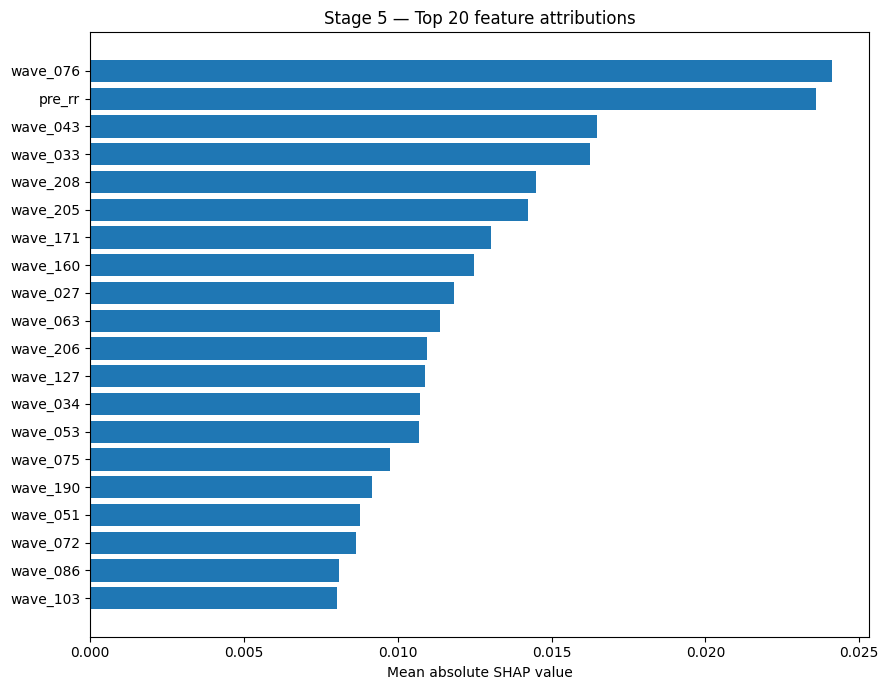

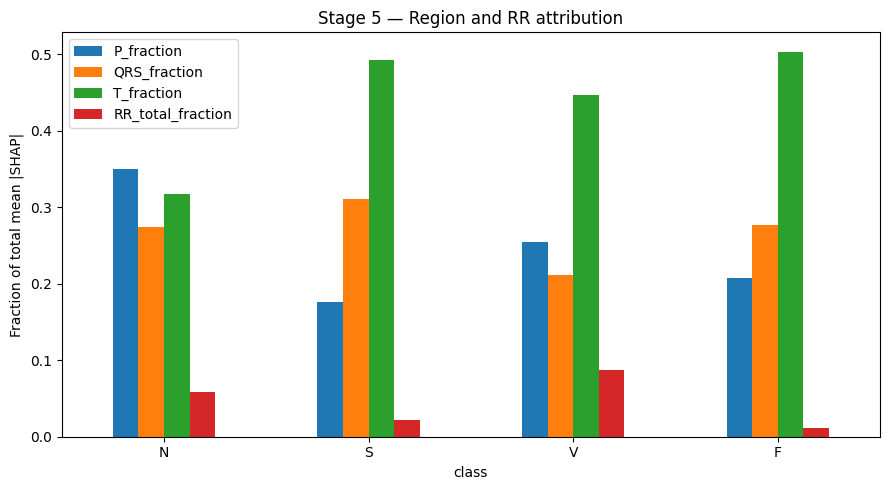

/tmp/ipykernel_2201/3150817750.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


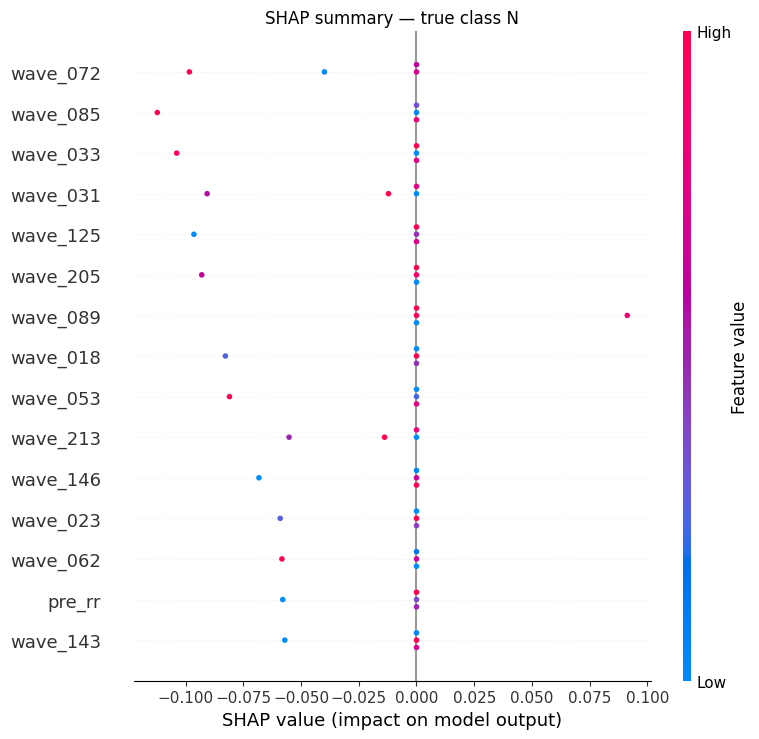

/tmp/ipykernel_2201/3150817750.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


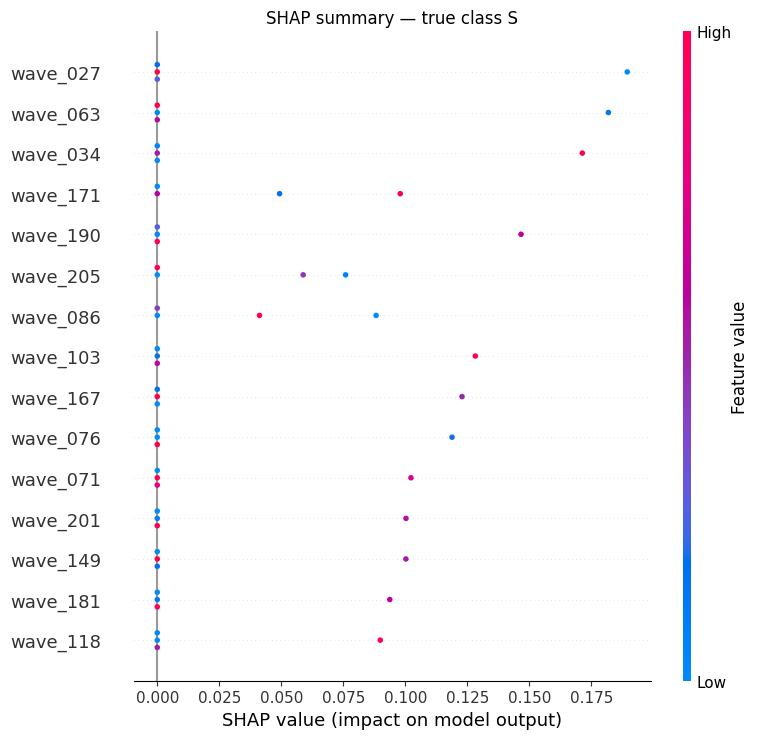

/tmp/ipykernel_2201/3150817750.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


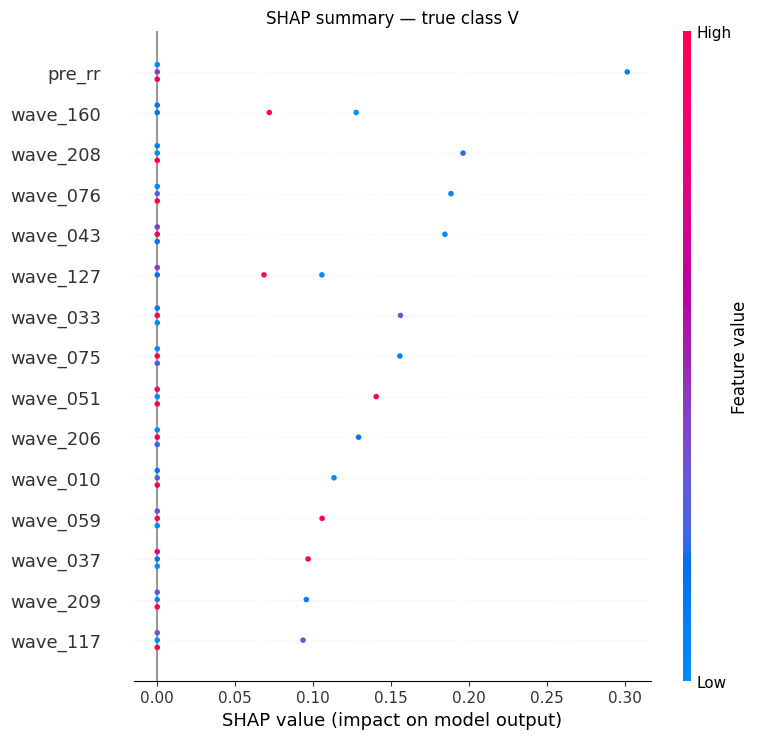

/tmp/ipykernel_2201/3150817750.py:28: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


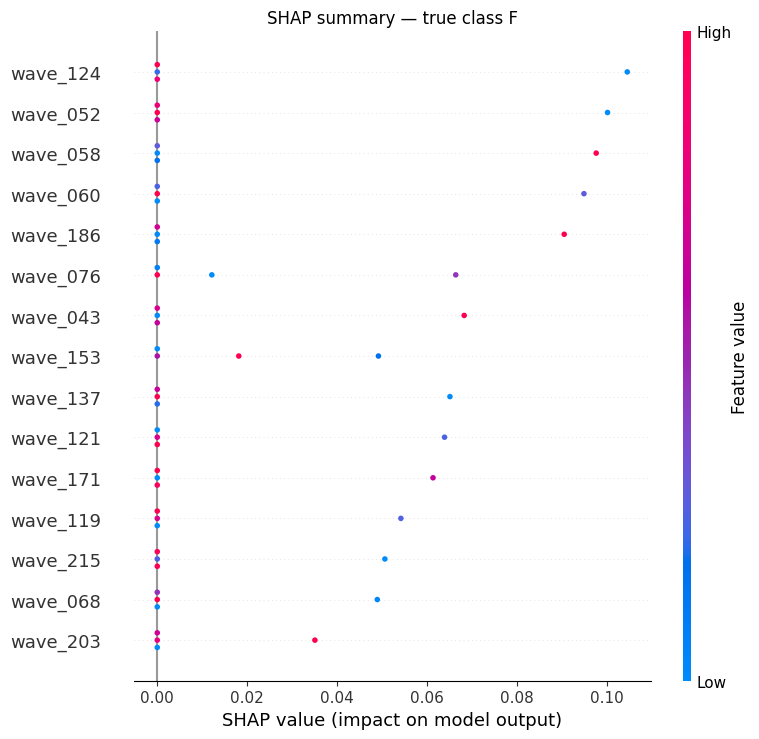

In [14]:
# Global feature importance (top 20)
top = feature_importance.head(20).sort_values("mean_abs_shap_true_class")
plt.figure(figsize=(9,7))
plt.barh(top["feature"], top["mean_abs_shap_true_class"])
plt.xlabel("Mean absolute SHAP value")
plt.title("Stage 5 — Top 20 feature attributions")
plt.tight_layout()
plt.savefig(OUT/"shap_top20_features.png", dpi=180)
plt.show()
plt.close()

# P/QRS/T/RR relative attribution by class
plot_df = region_df.set_index("class")[["P_fraction","QRS_fraction","T_fraction","RR_total_fraction"]]
ax = plot_df.plot(kind="bar", figsize=(9,5))
ax.set_ylabel("Fraction of total mean |SHAP|")
ax.set_title("Stage 5 — Region and RR attribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT/"shap_region_importance.png", dpi=180)
plt.show()
plt.close()

# Per-class feature beeswarm summary (SHAP's summary_plot supports one output at a time)
for cls in C.EVAL_LABELS:
    mask = true_labels == cls
    if not mask.any():
        continue
    shap.summary_plot(
        np.stack([sv[i, :, cls] for i in np.where(mask)[0]]),
        explain_matrix[mask],
        feature_names=FEATURE_NAMES,
        max_display=15,
        show=False
    )
    plt.title(f"SHAP summary — true class {C.CLASS_NAMES[cls]}")
    plt.tight_layout()
    plt.savefig(OUT/f"shap_summary_class_{C.CLASS_NAMES[cls]}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

## 13. Save reproducibility record and report

This records the exact dataset hashes, fold, model recipe, SHAP settings and outputs. It does not claim clinician validation.

In [15]:
summary = {
    "stage": 5,
    "status": "completed",
    "method": "KernelSHAP",
    "model": "CNN + Focal Loss + RR, seed 0",
    "fit_data": "DS1 only",
    "early_stopping_fold": 0,
    "explanation_data": "bounded DS2 class-stratified sample; explanatory only",
    "ds1_sha256": h1,
    "ds2_sha256": h2,
    "n_background": int(len(background)),
    "n_explained": int(len(explain_matrix)),
    "nsamples": int(NSAMPLES),
    "features": FEATURE_NAMES,
    "class_names": C.CLASS_NAMES,
    "evaluation_classes": C.EVAL_CLASSES,
    "segments": {k:list(v) for k,v in C.SEGMENTS.items()},
    "efficiency": efficiency,
    "faithfulness_summary": {
        "n_examples": int(len(faith_df)),
        "top20_drop_mean": float(faith_df["top20_probability_drop"].mean()),
        "random_drop_mean": float(faith_df["random_mask_drop_mean"].mean()),
        "top20_exceeds_random_fraction": float(faith_df["top20_drop_exceeds_random_mean"].mean())
    },
    "caveats": [
        "Attributions are model explanations, not causal evidence.",
        "P/QRS/T regions use the project's fixed sample boundaries and require cautious interpretation.",
        "Zero masking can create out-of-distribution waveforms.",
        "DS2 has historical prior-access disclosure in project records; it is not described as historically untouched."
    ]
}
(OUT/"stage5_explainability.json").write_text(json.dumps(summary, indent=2))

report = f'''# Stage 5 — SHAP Explainability

## Scope
- SHAP-based class-wise feature attribution.
- Selected model: CNN + Focal Loss + RR, seed 0.
- DS1-only fitting with frozen patient-held-out fold 0 for early stopping.
- Bounded class-stratified DS2 sample used for explanations only.

## Execution settings
- DS1 SHA256: `{h1}`
- DS2 SHA256: `{h2}`
- SHAP background rows: {len(background)}
- Explained examples: {len(explain_matrix)}
- KernelSHAP nsamples: {NSAMPLES}

## Region and RR attribution
{region_df.to_markdown(index=False)}

## Faithfulness summary
- Examples: {len(faith_df)}
- Mean top-20% masking probability drop: {faith_df["top20_probability_drop"].mean():.6f}
- Mean random masking probability drop: {faith_df["random_mask_drop_mean"].mean():.6f}
- Fraction where top-20% drop exceeds random mean: {faith_df["top20_drop_exceeds_random_mean"].mean():.3f}

## Model efficiency
- Device: {device}
- Trainable parameters: {n_params}
- Checkpoint bytes: {checkpoint_bytes}
- Mean batch-256 latency: {batch_latency_ms:.4f} ms
- Mean latency per beat: {batch_latency_ms/256:.6f} ms

## Limitations
Attributions describe model behaviour and do not establish causality or clinical validity. The perturbation baseline uses zero masking. DS2 historical-access disclosure is retained.
'''
(OUT/"STAGE5_REPORT.md").write_text(report)
print("Saved Stage 5 outputs to:", OUT)
print(sorted(p.name for p in OUT.iterdir()))

Saved Stage 5 outputs to: /content/AMAC-ECG/artifacts/stage5
['STAGE5_REPORT.md', 'models', 'shap_classwise_feature_importance.csv', 'shap_faithfulness_top20_vs_random.csv', 'shap_feature_importance.csv', 'shap_region_importance.csv', 'shap_region_importance.png', 'shap_summary_class_F.png', 'shap_summary_class_N.png', 'shap_summary_class_S.png', 'shap_summary_class_V.png', 'shap_top20_features.png', 'stage5_efficiency.json', 'stage5_explainability.json']


## 14. Package Stage 5 outputs

Creates a ZIP of Stage 5 results for download. The model checkpoint is included for reproducibility; the dataset itself is not copied into this ZIP.

In [16]:
stage5_zip = REPO / "AMAC_ECG_Stage5_SHAP_Results.zip"
if stage5_zip.exists():
    stage5_zip.unlink()
with zipfile.ZipFile(stage5_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(REPO))
# Include the exact helper module used by this notebook.
helper_path = REPO / "src" / "stage5_utils.py"
if helper_path.exists():
    with zipfile.ZipFile(stage5_zip, "a", zipfile.ZIP_DEFLATED) as z:
        z.write(helper_path, "stage5_utils.py")
print("Created:", stage5_zip, "size:", stage5_zip.stat().st_size)
from google.colab import files
files.download(str(stage5_zip))

Created: /content/AMAC-ECG/AMAC_ECG_Stage5_SHAP_Results.zip size: 1020175


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>